In [4]:
from google.colab import drive
import os

# Mount Google Drive to save work persistently
drive.mount('/content/drive')

# Define the main project path
project_path = '/content/drive/MyDrive/MarineSAM_Project'

# Define the subfolders we will need
folders = [
    'data/TrashCan/original',
    'data/TrashCan/masks',
    'data/SAM_segmented',
    'models/checkpoints',
    'results/figures'
]

# Create the directories if they don't already exist
for folder in folders:
    os.makedirs(os.path.join(project_path, folder), exist_ok=True)

print("Project folders created successfully in your Google Drive!")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project folders created successfully in your Google Drive!


In [2]:
import os
from google.colab import files

# 1. Upload the kaggle.json file you just downloaded
print("Please upload your kaggle.json file:")
uploaded = files.upload()

# 2. Set up Kaggle directory and permissions
os.environ['KAGGLE_CONFIG_DIR'] = '/content'
os.system('mkdir -p ~/.kaggle')
os.system('cp kaggle.json ~/.kaggle/')
os.system('chmod 600 ~/.kaggle/kaggle.json')

# 3. Navigate to the Drive folder we created in Step 1
%cd /content/drive/MyDrive/MarineSAM_Project/data/TrashCan/original

# 4. Download and unzip the dataset
# (Using the standard TrashCan 1.0 Kaggle identifier)
!kaggle datasets download -d mexwell/trashcan-1-0 --unzip

print("Dataset downloaded and unzipped successfully!")

Please upload your kaggle.json file:


Saving kaggle.json to kaggle.json
/content/drive/MyDrive/MarineSAM_Project/data/TrashCan/original
Dataset URL: https://www.kaggle.com/datasets/mexwell/trashcan-1-0
License(s): Attribution 4.0 International (CC BY 4.0)
100% 527M/527M [00:05<00:00, 108MB/s]


User cancelled operation
Dataset downloaded and unzipped successfully!


In [5]:
# 1. Navigate to the fast local Colab storage
%cd /content

# 2. Download the dataset locally (takes ~5 seconds)
!kaggle datasets download -d mexwell/trashcan-1-0

# 3. Unzip locally and quietly (-q) to a new folder
!unzip -q trashcan-1-0.zip -d /content/trashcan_data

print("Dataset downloaded and unzipped to local SSD successfully!")

/content
Dataset URL: https://www.kaggle.com/datasets/mexwell/trashcan-1-0
License(s): Attribution 4.0 International (CC BY 4.0)
100% 527M/527M [00:06<00:00, 85.4MB/s]

Dataset downloaded and unzipped to local SSD successfully!


--- Folder Structure ---
Directory: dataset

--- Image Inspection ---
Total images found: 21636
Sample image path: /content/trashcan_data/dataset/instance_version/val/vid_000139_frame0000012.jpg
Sample image shape (Height, Width, Channels): (270, 480, 3)


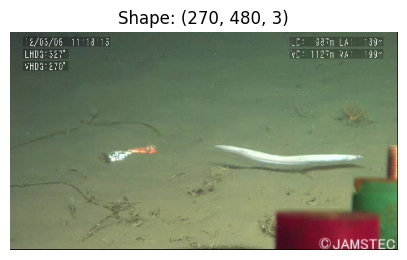

In [6]:
import os
import cv2
import random
import matplotlib.pyplot as plt

# The path where we extracted the dataset LOCALLY
data_dir = '/content/trashcan_data'

print("--- Folder Structure ---")
# List the top-level directories
try:
    for item in os.listdir(data_dir):
        if os.path.isdir(os.path.join(data_dir, item)):
            print(f"Directory: {item}")
        else:
            print(f"File: {item}")
except Exception as e:
    print(f"Error reading directory: {e}")

print("\n--- Image Inspection ---")
# Recursively find all image files
image_paths = []
for root, dirs, files in os.walk(data_dir):
    for file in files:
        if file.lower().endswith(('.jpg', '.jpeg', '.png')):
            image_paths.append(os.path.join(root, file))

if image_paths:
    print(f"Total images found: {len(image_paths)}")

    # Pick a random image to inspect
    sample_img_path = random.choice(image_paths)

    # Read the image
    img = cv2.imread(sample_img_path)

    if img is not None:
        # Convert BGR to RGB for Matplotlib
        img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        print(f"Sample image path: {sample_img_path}")
        print(f"Sample image shape (Height, Width, Channels): {img.shape}")

        # Display the image
        plt.figure(figsize=(5, 5))
        plt.imshow(img_rgb)
        plt.title(f"Shape: {img.shape}")
        plt.axis('off')
        plt.show()
    else:
        print(f"Failed to read image at: {sample_img_path}")
else:
    print("No images found! Check the extraction path.")

In [7]:
import json
import os
from collections import Counter

# Path to the material_version directory
material_dir = '/content/trashcan_data/dataset/material_version'

print("--- Subdirectories in material_version ---")
print(os.listdir(material_dir))

# Paths to the annotation JSON files
train_json_path = os.path.join(material_dir, 'instances_train_trashcan.json')
val_json_path = os.path.join(material_dir, 'instances_val_trashcan.json')

# Helper function to inspect COCO annotations
def inspect_coco_json(json_path, split_name):
    if not os.path.exists(json_path):
        print(f"Annotation file not found: {json_path}")
        return

    with open(json_path, 'r') as f:
        data = json.load(f)

    print(f"\n--- {split_name} Split Summary ---")
    print(f"Total Images: {len(data['images'])}")
    print(f"Total Annotations: {len(data['annotations'])}")

    # Extract category IDs and names
    categories = {cat['id']: cat['name'] for cat in data['categories']}
    print(f"Categories ({len(categories)}): {categories}")

    # Count occurrences per class
    class_counts = Counter([categories[ann['category_id']] for ann in data['annotations']])
    print("Class distribution:")
    for class_name, count in class_counts.items():
        print(f"  - {class_name}: {count}")

inspect_coco_json(train_json_path, 'TRAIN')
inspect_coco_json(val_json_path, 'VAL')

--- Subdirectories in material_version ---
['README.txt', 'instances_train_trashcan.json', 'val', 'train', 'instances_val_trashcan.json']

--- TRAIN Split Summary ---
Total Images: 6008
Total Annotations: 9741
Categories (16): {1: 'rov', 2: 'plant', 3: 'animal_fish', 4: 'animal_starfish', 5: 'animal_shells', 6: 'animal_crab', 7: 'animal_eel', 8: 'animal_etc', 9: 'trash_etc', 10: 'trash_fabric', 11: 'trash_fishing_gear', 12: 'trash_metal', 13: 'trash_paper', 14: 'trash_plastic', 15: 'trash_rubber', 16: 'trash_wood'}
Class distribution:
  - animal_etc: 180
  - plant: 405
  - animal_starfish: 274
  - rov: 2653
  - trash_plastic: 1490
  - trash_etc: 1630
  - animal_fish: 611
  - animal_shells: 171
  - trash_metal: 901
  - animal_eel: 267
  - trash_fabric: 247
  - trash_wood: 271
  - trash_fishing_gear: 127
  - trash_rubber: 113
  - animal_crab: 247
  - trash_paper: 154

--- VAL Split Summary ---
Total Images: 1204
Total Annotations: 2595
Categories (16): {1: 'rov', 2: 'plant', 3: 'animal_f

In [8]:
# 1. Install the official SAM repository from GitHub quietly
!pip install -q 'git+https://github.com/facebookresearch/segment-anything.git'

# 2. Download the pre-trained weights (checkpoint) for the vit_b model
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

import torch
from segment_anything import sam_model_registry, SamPredictor

print("SAM library installed and weights downloaded!")

# 3. Initialize the model and move it to the T4 GPU
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Using hardware: {device}")

sam_checkpoint = "sam_vit_b_01ec64.pth"
model_type = "vit_b"

try:
    sam = sam_model_registry[model_type](checkpoint=sam_checkpoint)
    sam.to(device=device)

    # We use SamPredictor so we can feed it bounding box prompts later
    predictor = SamPredictor(sam)
    print("SAM model successfully loaded into memory and ready for predictions!")
except Exception as e:
    print(f"Failed to load SAM: {e}")

  Preparing metadata (setup.py) ... done
SAM library installed and weights downloaded!
Using hardware: cpu
SAM model successfully loaded into memory and ready for predictions!


Passing image and bounding box to SAM...


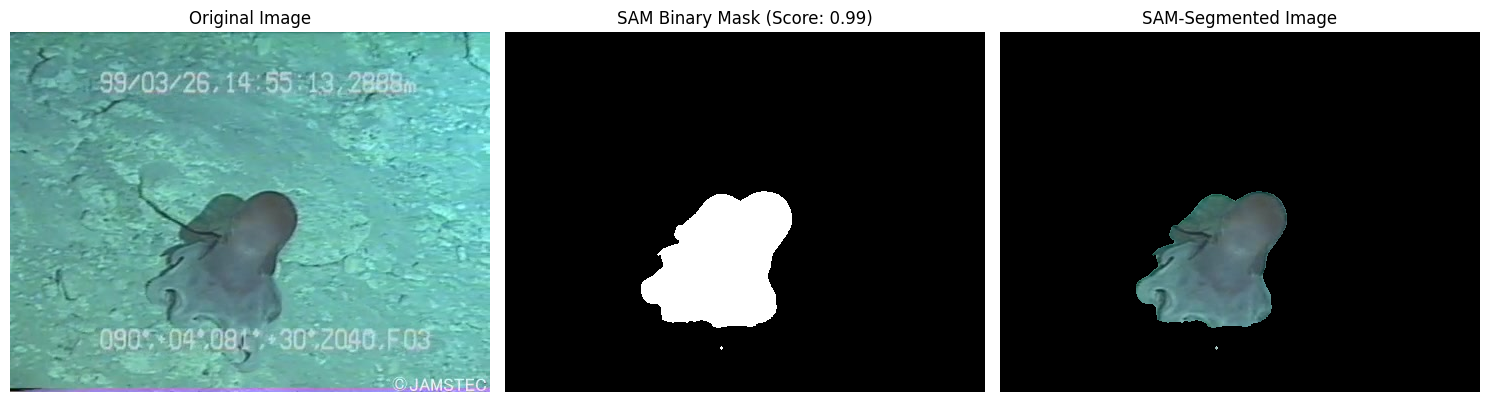

In [9]:
import json
import cv2
import numpy as np
import matplotlib.pyplot as plt
import os

# 1. Load the training annotations
json_path = '/content/trashcan_data/dataset/material_version/instances_train_trashcan.json'
img_dir = '/content/trashcan_data/dataset/material_version/train'

with open(json_path, 'r') as f:
    coco_data = json.load(f)

# 2. Pick the first annotation and its corresponding image
first_ann = coco_data['annotations'][0]
image_info = next(item for item in coco_data['images'] if item["id"] == first_ann['image_id'])

img_path = os.path.join(img_dir, image_info['file_name'])

# 3. Load the image using OpenCV
img = cv2.imread(img_path)
img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

# 4. Extract COCO Bounding Box and convert to SAM format
# COCO: [x, y, w, h] -> SAM: [x, y, x+w, y+h]
x, y, w, h = first_ann['bbox']
sam_bbox = np.array([x, y, x + w, y + h])

# 5. Generate the Mask using SAM
print("Passing image and bounding box to SAM...")
predictor.set_image(img_rgb)
masks, scores, _ = predictor.predict(
    box=sam_bbox,
    multimask_output=False # We only want the highest confidence mask
)

# 6. Apply the mask to isolate the debris (Object-centric feature extraction)
binary_mask = masks[0]
segmented_img = img_rgb.copy()
# Wherever the mask is False (background), set the pixel color to black (0,0,0)
segmented_img[~binary_mask] = [0, 0, 0]

# 7. Visualize the results
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(img_rgb)
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(binary_mask, cmap='gray')
axes[1].set_title(f"SAM Binary Mask (Score: {scores[0]:.2f})")
axes[1].axis('off')

axes[2].imshow(segmented_img)
axes[2].set_title("SAM-Segmented Image")
axes[2].axis('off')

plt.tight_layout()
plt.show()

In [1]:
import torch
import os

# 1. HARDWARE CHECK
if not torch.cuda.is_available():
    raise RuntimeError("🚨 NO GPU DETECTED! Stop and change your runtime to T4 GPU. 🚨")
print(f"✅ GPU Detected: {torch.cuda.get_device_name(0)}")

# 2. FAST LOCAL UNZIP
%cd /content
!kaggle datasets download -d mexwell/trashcan-1-0
!unzip -q trashcan-1-0.zip -d /content/trashcan_data
print("✅ Data Unzipped!")

# 3. SAM INSTALL & LOAD
!pip install -q 'git+https://github.com/facebookresearch/segment-anything.git'
!wget -q https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

from segment_anything import sam_model_registry, SamPredictor
sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth")
sam.to(device="cuda")
predictor = SamPredictor(sam)
print("✅ SAM Loaded on GPU!")

✅ GPU Detected: Tesla T4
/content
Dataset URL: https://www.kaggle.com/datasets/mexwell/trashcan-1-0
License(s): Attribution 4.0 International (CC BY 4.0)
100% 527M/527M [00:02<00:00, 192MB/s]

✅ Data Unzipped!
  Preparing metadata (setup.py) ... done
✅ SAM Loaded on GPU!


In [4]:
import json
import cv2
import numpy as np
import os
from tqdm import tqdm
import torch
from collections import defaultdict

# 1. Define paths (Local SSD for speed)
json_path = '/content/trashcan_data/dataset/material_version/instances_train_trashcan.json'
img_dir = '/content/trashcan_data/dataset/material_version/train'

local_base = '/content/processed_224'
out_orig = os.path.join(local_base, 'original_train')
out_seg = os.path.join(local_base, 'segmented_train')

os.makedirs(out_orig, exist_ok=True)
os.makedirs(out_seg, exist_ok=True)

# 2. Load annotations
print("Loading annotations...")
with open(json_path, 'r') as f:
    coco_data = json.load(f)

img_dict = {img['id']: img['file_name'] for img in coco_data['images']}

# 3. Group annotations by image_id for speed
ann_by_image = defaultdict(list)
for ann in coco_data['annotations']:
    ann_by_image[ann['image_id']].append(ann)

images_to_process = [img_id for img_id in img_dict.keys() if img_id in ann_by_image]
print(f"Total unique images to process: {len(images_to_process)}")
print(f"Total trash items to extract: {len(coco_data['annotations'])}")

# 4. Process loop
count_processed = 0

for img_id in tqdm(images_to_process, desc="Processing Images"):
    file_name = img_dict[img_id]
    img_path = os.path.join(img_dir, file_name)

    img = cv2.imread(img_path)
    if img is None:
        continue

    img_rgb = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    # Run the heavy SAM encoder ONLY ONCE per image
    predictor.set_image(img_rgb)

    # Loop through all the trash items in this specific image
    for ann in ann_by_image[img_id]:
        ann_id = ann['id']
        save_name = f"{file_name.split('.')[0]}_ann{ann_id}.jpg"
        orig_save_path = os.path.join(out_orig, save_name)
        seg_save_path = os.path.join(out_seg, save_name)

        x, y, w, h = ann['bbox']
        sam_bbox = np.array([x, y, x + w, y + h])

        # Predict mask
        masks, _, _ = predictor.predict(box=sam_bbox, multimask_output=False)
        binary_mask = masks[0]

        segmented_img = img_rgb.copy()
        segmented_img[~binary_mask] = [0, 0, 0]

        # Resize both to 224x224
        orig_resized = cv2.resize(img_rgb, (224, 224))
        seg_resized = cv2.resize(segmented_img, (224, 224))

        # Save locally
        cv2.imwrite(orig_save_path, cv2.cvtColor(orig_resized, cv2.COLOR_RGB2BGR))
        cv2.imwrite(seg_save_path, cv2.cvtColor(seg_resized, cv2.COLOR_RGB2BGR))

        count_processed += 1

    # Prevent GPU memory leaks
    if count_processed % 100 == 0:
        torch.cuda.empty_cache()

print(f"\nFinished! Processed {count_processed} total trash items.")

Loading annotations...
Total unique images to process: 6008
Total trash items to extract: 9741


Processing Images: 100%|██████████| 6008/6008 [46:59<00:00,  2.13it/s]


Finished! Processed 9741 total trash items.


In [5]:
import os
from google.colab import drive

# 1. Ensure Drive is still mounted
if not os.path.exists('/content/drive/MyDrive'):
    drive.mount('/content/drive')

print("Zipping the processed images... (This might take 2-3 minutes)")
# 2. Zip the folder quietly (-q) and recursively (-r)
!zip -qr /content/processed_train_data.zip /content/processed_224

print("Zip complete! Moving to Google Drive...")
# 3. Copy the zip file to your persistent Drive folder
!cp /content/processed_train_data.zip /content/drive/MyDrive/MarineSAM_Project/data/

print("✅ SUCCESS: Data securely saved to Google Drive!")

Mounted at /content/drive
Zipping the processed images... (This might take 2-3 minutes)
Zip complete! Moving to Google Drive...
✅ SUCCESS: Data securely saved to Google Drive!


In [7]:
import os
import json
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image

# Exact 6-class mapping based on the assignment poster
RAW_TO_6CLASS = {
    'trash_plastic': 'Plastic',
    'trash_metal': 'Metal',
    'trash_fabric': 'Cloth/Rope',
    'trash_fishing_gear': 'Cloth/Rope',
    'trash_rubber': 'Rubber',
    'trash_paper': 'Paper',
    'trash_etc': 'Plastic' # Standard benchmark grouping or ignore
}

TARGET_CLASSES = ['Plastic', 'Glass', 'Metal', 'Cloth/Rope', 'Rubber', 'Paper']
CLASS_TO_IDX = {name: idx for idx, name in enumerate(TARGET_CLASSES)}

class FilteredMarineDebrisDataset(Dataset):
    def __init__(self, json_path, orig_dir, seg_dir, transform=None):
        self.orig_dir = orig_dir
        self.seg_dir = seg_dir
        self.transform = transform

        with open(json_path, 'r') as f:
            self.coco = json.load(f)

        cat_id_to_name = {cat['id']: cat['name'] for cat in self.coco['categories']}

        self.data = []
        for ann in self.coco['annotations']:
            raw_name = cat_id_to_name[ann['category_id']]

            # Keep only items that map to our 6 debris classes
            if raw_name in RAW_TO_6CLASS:
                mapped_name = RAW_TO_6CLASS[raw_name]
                label_idx = CLASS_TO_IDX[mapped_name]

                img_info = next(item for item in self.coco['images'] if item['id'] == ann['image_id'])
                file_name = img_info['file_name']
                ann_id = ann['id']

                save_name = f"{file_name.split('.')[0]}_ann{ann_id}.jpg"
                orig_path = os.path.join(self.orig_dir, save_name)
                seg_path = os.path.join(self.seg_dir, save_name)

                if os.path.exists(orig_path) and os.path.exists(seg_path):
                    self.data.append({
                        'orig_path': orig_path,
                        'seg_path': seg_path,
                        'label': label_idx
                    })

    def __len__(self):
        return len(self.data)

    def __getitem__(self, idx):
        item = self.data[idx]
        orig_img = Image.open(item['orig_path']).convert('RGB')
        seg_img = Image.open(item['seg_path']).convert('RGB')
        label = item['label']

        if self.transform:
            orig_img = self.transform(orig_img)
            seg_img = self.transform(seg_img)

        return orig_img, seg_img, label

# Transform pipeline
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

json_path = '/content/trashcan_data/dataset/material_version/instances_train_trashcan.json'
orig_dir = '/content/processed_224/original_train'
seg_dir = '/content/processed_224/segmented_train'

train_dataset = FilteredMarineDebrisDataset(json_path, orig_dir, seg_dir, transform=transform)

print(f"✅ Filtered Dataset successfully created!")
print(f"Total marine debris samples: {len(train_dataset)}")
print(f"Active Class Mapping: {CLASS_TO_IDX}")

✅ Filtered Dataset successfully created!
Total marine debris samples: 4662
Active Class Mapping: {'Plastic': 0, 'Glass': 1, 'Metal': 2, 'Cloth/Rope': 3, 'Rubber': 4, 'Paper': 5}


In [8]:
import torch.nn as nn
from torchvision import models
from torch.utils.data import DataLoader

# 1. Create the DataLoader
# The poster suggests batch size 16 or 32. We'll try 32 for speed.
# If it crashes later, we drop it to 16.
train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True, num_workers=2)
print("✅ DataLoader initialized!")

# 2. Initialize the Baseline Model (MobileNetV3-Small)
# We use pre-trained weights (transfer learning) so it learns faster.
model_a1 = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)

# 3. Modify the classifier head for 6 classes
# We find the in_features of the final layer and replace it.
num_features = model_a1.classifier[3].in_features
model_a1.classifier[3] = nn.Linear(num_features, 6)

# 4. Move model to GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model_a1 = model_a1.to(device)

print(f"✅ Model successfully loaded and moved to {device}!")
print(f"✅ Final layer modified to output {model_a1.classifier[3].out_features} classes.")

✅ DataLoader initialized!
Downloading: "https://download.pytorch.org/models/mobilenet_v3_small-047dcff4.pth" to /root/.cache/torch/hub/checkpoints/mobilenet_v3_small-047dcff4.pth


100%|██████████| 9.83M/9.83M [00:00<00:00, 132MB/s]

✅ Model successfully loaded and moved to cuda!
✅ Final layer modified to output 6 classes.


In [9]:
import torch.optim as optim
from tqdm import tqdm

# 1. Define Loss and Optimizer (Required by assignment)
criterion = nn.CrossEntropyLoss()
# AdamW is great for Vision Models. Learning rate 0.001 is a safe starting point.
optimizer = optim.AdamW(model_a1.parameters(), lr=0.001)

# 2. Dry Run Parameters
epochs = 1
print("🚀 Starting Baseline A1 Dry Run (1 Epoch)...")

# 3. Training Loop
model_a1.train() # Set model to training mode
for epoch in range(epochs):
    running_loss = 0.0

    # We use tqdm to get a nice progress bar for the batches
    loop = tqdm(train_loader, leave=True)
    for batch_idx, (orig_img, seg_img, labels) in enumerate(loop):

        # Move data to GPU
        # For A1, we ONLY use orig_img
        orig_img = orig_img.to(device)
        labels = labels.to(device)

        # Zero the gradients
        optimizer.zero_grad()

        # Forward pass
        outputs = model_a1(orig_img)
        loss = criterion(outputs, labels)

        # Backward pass (calculate gradients)
        loss.backward()

        # Update weights
        optimizer.step()

        running_loss += loss.item()

        # Update the progress bar with the current loss
        loop.set_description(f"Epoch [{epoch+1}/{epochs}]")
        loop.set_postfix(loss=loss.item())

    epoch_loss = running_loss / len(train_loader)
    print(f"✅ Epoch {epoch+1} completed! Average Loss: {epoch_loss:.4f}")

🚀 Starting Baseline A1 Dry Run (1 Epoch)...


Epoch [1/1]: 100%|██████████| 146/146 [00:19<00:00,  7.67it/s, loss=0.444]

✅ Epoch 1 completed! Average Loss: 0.5289


In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, random_split
from torchvision import models
from tqdm import tqdm
import copy

# 1. Split the dataset (80% Train, 20% Validation)
total_size = len(train_dataset)
train_size = int(0.8 * total_size)
val_size = total_size - train_size

# Fixed seed for reproducibility (Assignment Guideline #15)
generator = torch.Generator().manual_seed(42)
train_subset, val_subset = random_split(train_dataset, [train_size, val_size], generator=generator)

# Re-create loaders
train_loader = DataLoader(train_subset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_subset, batch_size=32, shuffle=False)
print(f"✅ Data split: {train_size} training, {val_size} validation.")

# 2. Re-initialize a fresh model
model_a1 = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
model_a1.classifier[3] = nn.Linear(model_a1.classifier[3].in_features, 6)
model_a1 = model_a1.to(device)

# 3. Setup Training parameters
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model_a1.parameters(), lr=0.001)

epochs = 20
patience = 3 # Early stopping tolerance
best_val_loss = float('inf')
epochs_no_improve = 0
best_model_wts = copy.deepcopy(model_a1.state_dict())

print("🚀 Starting Full Training for Baseline A1 (Original Images)...")

# 4. The Training Loop
for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model_a1.train()
    running_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for orig_img, seg_img, labels in loop:
        orig_img, labels = orig_img.to(device), labels.to(device)

        optimizer.zero_grad()
        outputs = model_a1(orig_img)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # --- VALIDATION PHASE ---
    model_a1.eval()
    val_loss = 0.0
    corrects = 0

    with torch.no_grad():
        for orig_img, seg_img, labels in val_loader:
            orig_img, labels = orig_img.to(device), labels.to(device)
            outputs = model_a1(orig_img)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = corrects.double() / val_size

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # --- EARLY STOPPING CHECK ---
    if avg_val_loss < best_val_loss:
        best_val_loss = avg_val_loss
        best_model_wts = copy.deepcopy(model_a1.state_dict())
        epochs_no_improve = 0
        # Save securely to Drive
        torch.save(best_model_wts, '/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a1.pth')
    else:
        epochs_no_improve += 1
        if epochs_no_improve >= patience:
            print("🛑 Early stopping triggered! Validation loss stopped improving.")
            break

# 5. Restore best weights
model_a1.load_state_dict(best_model_wts)
print("✅ Training Complete! Best model saved to Google Drive.")

✅ Data split: 3729 training, 933 validation.
🚀 Starting Full Training for Baseline A1 (Original Images)...


Epoch 1/20 | Train Loss: 0.5914 | Val Loss: 0.9025 | Val Acc: 0.5884


Epoch 2/20 | Train Loss: 0.3230 | Val Loss: 0.7957 | Val Acc: 0.7717


Epoch 3/20 | Train Loss: 0.2662 | Val Loss: 0.3239 | Val Acc: 0.8810


Epoch 4/20 | Train Loss: 0.2055 | Val Loss: 0.4113 | Val Acc: 0.8574


Epoch 5/20 | Train Loss: 0.2011 | Val Loss: 0.3586 | Val Acc: 0.8532


Epoch 6/20 | Train Loss: 0.1865 | Val Loss: 0.3246 | Val Acc: 0.8639
🛑 Early stopping triggered! Validation loss stopped improving.
✅ Training Complete! Best model saved to Google Drive.


In [11]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm import tqdm

# 1. Initialize a fresh model for A2
model_a2 = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
model_a2.classifier[3] = nn.Linear(model_a2.classifier[3].in_features, 6)
model_a2 = model_a2.to(device)

# 2. Setup Training parameters
criterion = nn.CrossEntropyLoss()
optimizer_a2 = optim.AdamW(model_a2.parameters(), lr=0.001)

epochs = 20
patience = 3
best_val_loss_a2 = float('inf')
epochs_no_improve_a2 = 0
best_model_wts_a2 = copy.deepcopy(model_a2.state_dict())

print("🚀 Starting Full Training for Baseline A2 (SAM-Segmented Images)...")

# 3. The Training Loop
for epoch in range(epochs):
    # --- TRAINING PHASE ---
    model_a2.train()
    running_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for orig_img, seg_img, labels in loop:
        # CRITICAL CHANGE: We feed seg_img to the model instead of orig_img
        seg_img, labels = seg_img.to(device), labels.to(device)

        optimizer_a2.zero_grad()
        outputs = model_a2(seg_img)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_a2.step()
        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # --- VALIDATION PHASE ---
    model_a2.eval()
    val_loss = 0.0
    corrects = 0

    with torch.no_grad():
        for orig_img, seg_img, labels in val_loader:
            # CRITICAL CHANGE: We feed seg_img during validation too
            seg_img, labels = seg_img.to(device), labels.to(device)
            outputs = model_a2(seg_img)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = corrects.double() / val_size

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # --- EARLY STOPPING CHECK ---
    if avg_val_loss < best_val_loss_a2:
        best_val_loss_a2 = avg_val_loss
        best_model_wts_a2 = copy.deepcopy(model_a2.state_dict())
        epochs_no_improve_a2 = 0
        # Save securely to Drive as best_model_a2
        torch.save(best_model_wts_a2, '/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a2.pth')
    else:
        epochs_no_improve_a2 += 1
        if epochs_no_improve_a2 >= patience:
            print("🛑 Early stopping triggered! Validation loss stopped improving.")
            break

# 4. Restore best weights
model_a2.load_state_dict(best_model_wts_a2)
print("✅ Training Complete! Best model A2 saved to Google Drive.")

🚀 Starting Full Training for Baseline A2 (SAM-Segmented Images)...


Epoch 1/20 | Train Loss: 0.8399 | Val Loss: 0.9527 | Val Acc: 0.7031


Epoch 2/20 | Train Loss: 0.5459 | Val Loss: 2.1099 | Val Acc: 0.3633


Epoch 3/20 | Train Loss: 0.4035 | Val Loss: 1.1469 | Val Acc: 0.5584


Epoch 4/20 | Train Loss: 0.3254 | Val Loss: 2.1069 | Val Acc: 0.2862
🛑 Early stopping triggered! Validation loss stopped improving.
✅ Training Complete! Best model A2 saved to Google Drive.


In [12]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from torchvision import models
from tqdm import tqdm

# 1. Define the Simple Fusion Architecture
class SimpleConcatFusionNet(nn.Module):
    def __init__(self, num_classes=6):
        super(SimpleConcatFusionNet, self).__init__()

        # Branch A: Original Image Backbone
        self.backbone_orig = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        # Remove the final classification layer to just get the raw features (size 576)
        self.orig_features_size = self.backbone_orig.classifier[0].in_features
        self.backbone_orig.classifier = nn.Identity()

        # Branch B: SAM Image Backbone
        self.backbone_seg = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        self.seg_features_size = self.backbone_seg.classifier[0].in_features
        self.backbone_seg.classifier = nn.Identity()

        # Fusion Layer: Concatenate both (576 + 576 = 1152) and map to 6 classes
        self.fc = nn.Linear(self.orig_features_size + self.seg_features_size, num_classes)

    def forward(self, x_orig, x_seg):
        # Extract features
        feat_orig = self.backbone_orig(x_orig)
        feat_seg = self.backbone_seg(x_seg)

        # Concatenate along the feature dimension (dim=1)
        fused = torch.cat((feat_orig, feat_seg), dim=1)

        # Classify
        out = self.fc(fused)
        return out

# 2. Initialize Model A3
model_a3 = SimpleConcatFusionNet(num_classes=6).to(device)

# 3. Setup Training parameters
criterion = nn.CrossEntropyLoss()
optimizer_a3 = optim.AdamW(model_a3.parameters(), lr=0.001)

epochs = 20
patience = 3
best_val_loss_a3 = float('inf')
epochs_no_improve_a3 = 0
best_model_wts_a3 = copy.deepcopy(model_a3.state_dict())

print("🚀 Starting Full Training for Baseline A3 (Concat Fusion)...")

# 4. The Training Loop
for epoch in range(epochs):
    # --- TRAINING ---
    model_a3.train()
    running_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for orig_img, seg_img, labels in loop:
        # We pass BOTH images to the GPU
        orig_img, seg_img, labels = orig_img.to(device), seg_img.to(device), labels.to(device)

        optimizer_a3.zero_grad()
        # Feed BOTH images to the model
        outputs = model_a3(orig_img, seg_img)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_a3.step()
        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # --- VALIDATION ---
    model_a3.eval()
    val_loss = 0.0
    corrects = 0

    with torch.no_grad():
        for orig_img, seg_img, labels in val_loader:
            orig_img, seg_img, labels = orig_img.to(device), seg_img.to(device), labels.to(device)
            outputs = model_a3(orig_img, seg_img)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = corrects.double() / val_size

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # --- EARLY STOPPING ---
    if avg_val_loss < best_val_loss_a3:
        best_val_loss_a3 = avg_val_loss
        best_model_wts_a3 = copy.deepcopy(model_a3.state_dict())
        epochs_no_improve_a3 = 0
        torch.save(best_model_wts_a3, '/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a3.pth')
    else:
        epochs_no_improve_a3 += 1
        if epochs_no_improve_a3 >= patience:
            print("🛑 Early stopping triggered! Validation loss stopped improving.")
            break

# 5. Restore best weights
model_a3.load_state_dict(best_model_wts_a3)
print("✅ Training Complete! Best model A3 saved to Google Drive.")

🚀 Starting Full Training for Baseline A3 (Concat Fusion)...


Epoch 1/20 | Train Loss: 0.5671 | Val Loss: 0.8732 | Val Acc: 0.7942


Epoch 2/20 | Train Loss: 0.2506 | Val Loss: 0.5582 | Val Acc: 0.8039


Epoch 3/20 | Train Loss: 0.1841 | Val Loss: 0.3000 | Val Acc: 0.8896


Epoch 4/20 | Train Loss: 0.1331 | Val Loss: 0.7941 | Val Acc: 0.7728


Epoch 5/20 | Train Loss: 0.0986 | Val Loss: 0.3459 | Val Acc: 0.8853


Epoch 6/20 | Train Loss: 0.0738 | Val Loss: 0.3183 | Val Acc: 0.8789
🛑 Early stopping triggered! Validation loss stopped improving.
✅ Training Complete! Best model A3 saved to Google Drive.


In [13]:
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models

class MDMAM_Net(nn.Module):
    def __init__(self, num_classes=6):
        super(MDMAM_Net, self).__init__()

        # 1. Backbones (Extracting spatial feature maps, not flat vectors)
        # We use .features to get the C x H x W maps before global pooling
        mobilenet_orig = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        self.features_orig = mobilenet_orig.features

        mobilenet_seg = models.mobilenet_v3_small(weights=models.MobileNet_V3_Small_Weights.DEFAULT)
        self.features_seg = mobilenet_seg.features

        # MobileNetV3-Small final feature map has 576 channels
        channels = 576

        # 2. MDMAM Linear Projections (using 1x1 and 3x3 Convs as per standard vision attention)
        self.query_conv = nn.Conv2d(channels, channels, kernel_size=1) # W_Q applied to Context
        self.key_conv = nn.Conv2d(channels, channels, kernel_size=1)   # W_K applied to Object
        self.value_conv = nn.Conv2d(channels, channels, kernel_size=3, padding=1) # W_V applied to Object

        # 3. Final Classification Head
        self.gap = nn.AdaptiveAvgPool2d((1, 1)) # Global Average Pooling
        self.classifier = nn.Linear(channels, num_classes)

    def forward(self, x_orig, x_seg):
        # Extract C x H x W feature maps
        F_ctx = self.features_orig(x_orig)
        F_obj = self.features_seg(x_seg)

        B, C, H, W = F_ctx.size()
        N = H * W # Total spatial locations

        # --- Multi-Scale Attention Module (MDMAM) ---

        # Generate Q, K, V
        proj_query = self.query_conv(F_ctx).view(B, C, N).permute(0, 2, 1) # B x N x C
        proj_key = self.key_conv(F_obj).view(B, C, N)                      # B x C x N
        proj_value = self.value_conv(F_obj).view(B, C, N)                  # B x C x N

        # Attention = Softmax(Q * K^T / sqrt(d))
        energy = torch.bmm(proj_query, proj_key) / (C ** 0.5)              # B x N x N
        attention = F.softmax(energy, dim=-1)                              # A

        # F_att = A * V
        out = torch.bmm(proj_value, attention.permute(0, 2, 1))            # B x C x N
        F_att = out.view(B, C, H, W)

        # Residual Fusion: F_fusion = F_ctx + F_att
        F_fusion = F_ctx + F_att

        # --- Classification ---
        pooled = self.gap(F_fusion).view(B, C)
        logits = self.classifier(pooled)

        return logits

# Initialize the model to check for errors
try:
    model_proposed = MDMAM_Net(num_classes=6).to(device)
    print("✅ MDMAM Architecture successfully initialized on GPU!")

    # Test with dummy data to ensure tensor dimensions match perfectly
    dummy_orig = torch.randn(2, 3, 224, 224).to(device)
    dummy_seg = torch.randn(2, 3, 224, 224).to(device)
    dummy_out = model_proposed(dummy_orig, dummy_seg)
    print(f"✅ Forward pass successful! Output shape: {dummy_out.shape} (Expected: [2, 6])")
except Exception as e:
    print(f"🚨 Architecture Error: {e}")

✅ MDMAM Architecture successfully initialized on GPU!
✅ Forward pass successful! Output shape: torch.Size([2, 6]) (Expected: [2, 6])


In [14]:
import copy
import torch
import torch.nn as nn
import torch.optim as optim
from tqdm import tqdm

# 1. Setup Training parameters for MDMAM
criterion = nn.CrossEntropyLoss()
optimizer_proposed = optim.AdamW(model_proposed.parameters(), lr=0.001)

epochs = 20
patience = 3
best_val_loss_proposed = float('inf')
epochs_no_improve_proposed = 0
best_model_wts_proposed = copy.deepcopy(model_proposed.state_dict())

print("🚀 Starting Full Training for Proposed MDMAM (Original + SAM Features)...")

# 2. The Training Loop
for epoch in range(epochs):
    # --- TRAINING ---
    model_proposed.train()
    running_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for orig_img, seg_img, labels in loop:
        orig_img, seg_img, labels = orig_img.to(device), seg_img.to(device), labels.to(device)

        optimizer_proposed.zero_grad()
        outputs = model_proposed(orig_img, seg_img)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer_proposed.step()
        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # --- VALIDATION ---
    model_proposed.eval()
    val_loss = 0.0
    corrects = 0

    with torch.no_grad():
        for orig_img, seg_img, labels in val_loader:
            orig_img, seg_img, labels = orig_img.to(device), seg_img.to(device), labels.to(device)
            outputs = model_proposed(orig_img, seg_img)
            loss = criterion(outputs, labels)
            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = corrects.double() / val_size

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f}")

    # --- EARLY STOPPING ---
    if avg_val_loss < best_val_loss_proposed:
        best_val_loss_proposed = avg_val_loss
        best_model_wts_proposed = copy.deepcopy(model_proposed.state_dict())
        epochs_no_improve_proposed = 0
        # Saving as A5 to match your ablation study ID
        torch.save(best_model_wts_proposed, '/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a5.pth')
    else:
        epochs_no_improve_proposed += 1
        if epochs_no_improve_proposed >= patience:
            print("🛑 Early stopping triggered! Validation loss stopped improving.")
            break

# 3. Restore best weights
model_proposed.load_state_dict(best_model_wts_proposed)
print("✅ Training Complete! Best proposed model (A5) saved to Google Drive.")

🚀 Starting Full Training for Proposed MDMAM (Original + SAM Features)...


Epoch 1/20 | Train Loss: 0.7623 | Val Loss: 1.1917 | Val Acc: 0.6367


Epoch 2/20 | Train Loss: 0.4046 | Val Loss: 0.6263 | Val Acc: 0.7674


Epoch 3/20 | Train Loss: 0.2789 | Val Loss: 0.4505 | Val Acc: 0.8617


Epoch 4/20 | Train Loss: 0.2219 | Val Loss: 0.6892 | Val Acc: 0.8499


Epoch 5/20 | Train Loss: 0.1932 | Val Loss: 0.5756 | Val Acc: 0.8296


Epoch 6/20 | Train Loss: 0.1926 | Val Loss: 0.6471 | Val Acc: 0.8457
🛑 Early stopping triggered! Validation loss stopped improving.
✅ Training Complete! Best proposed model (A5) saved to Google Drive.


In [15]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, loader, model_type, class_names):
    model.eval()
    all_preds = []
    all_labels = []

    print(f"Running inference on validation set...")
    with torch.no_grad():
        for orig_img, seg_img, labels in loader:
            labels = labels.to(device)

            # Route the inputs based on the architecture
            if model_type == 'single_orig':
                outputs = model(orig_img.to(device))
            elif model_type == 'single_seg':
                outputs = model(seg_img.to(device))
            else: # fusion architectures (A3, A5)
                outputs = model(orig_img.to(device), seg_img.to(device))

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # 1. Generate the Scikit-Learn Classification Report
    print(f"\n--- Detailed Performance Metrics ---")
    report = classification_report(all_labels, all_preds, target_names=class_names, digits=4)
    print(report)

    # 2. Plot a clean, minimalist Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds)
    plt.figure(figsize=(8, 6))

    # Using a clean blue gradient to fit a modern aesthetic
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor='white')

    plt.ylabel('Actual Debris Class (Ground Truth)', fontweight='bold')
    plt.xlabel('Predicted Debris Class', fontweight='bold')
    plt.title(f'Confusion Matrix', pad=15)
    plt.tight_layout()
    plt.show()

# Extract the class names in the correct order (0 to 5)
class_names = [name for name, idx in sorted(CLASS_TO_IDX.items(), key=lambda item: item[1])]

# Let's evaluate the model that is currently in memory (A5 - Proposed MDMAM)
print("Evaluating Proposed MDMAM Model (A5)...")
evaluate_model(model_proposed, val_loader, 'fusion', class_names)

Evaluating Proposed MDMAM Model (A5)...
Running inference on validation set...

--- Detailed Performance Metrics ---


ValueError: Number of classes, 5, does not match size of target_names, 6. Try specifying the labels parameter

Evaluating Proposed MDMAM Model (A5)...
Running inference on validation set...

--- Detailed Performance Metrics ---
              precision    recall  f1-score   support

     Plastic     0.8720    0.9421    0.9057       622
       Glass     0.0000    0.0000    0.0000         0
       Metal     0.8827    0.7730    0.8242       185
  Cloth/Rope     0.6615    0.6143    0.6370        70
      Rubber     1.0000    0.7619    0.8649        21
       Paper     0.8889    0.4571    0.6038        35

    accuracy                         0.8617       933
   macro avg     0.7175    0.5914    0.6393       933
weighted avg     0.8619    0.8617    0.8572       933



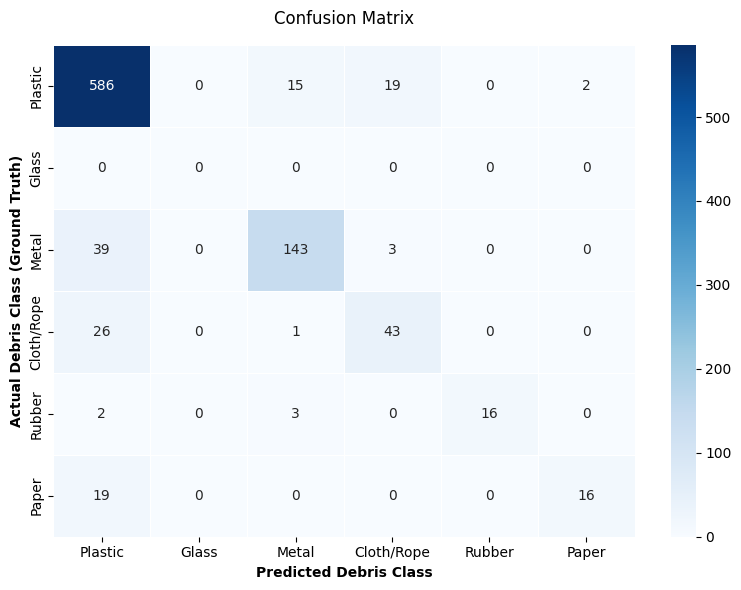

In [16]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

def evaluate_model(model, loader, model_type, class_names):
    model.eval()
    all_preds = []
    all_labels = []

    print(f"Running inference on validation set...")
    with torch.no_grad():
        for orig_img, seg_img, labels in loader:
            labels = labels.to(device)

            # Route the inputs based on the architecture
            if model_type == 'single_orig':
                outputs = model(orig_img.to(device))
            elif model_type == 'single_seg':
                outputs = model(seg_img.to(device))
            else: # fusion architectures (A3, A5)
                outputs = model(orig_img.to(device), seg_img.to(device))

            _, preds = torch.max(outputs, 1)
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.cpu().numpy())

    # FIXED: Explicitly provide the label indices [0, 1, 2, 3, 4, 5]
    label_indices = list(range(len(class_names)))

    # 1. Generate the Scikit-Learn Classification Report
    print(f"\n--- Detailed Performance Metrics ---")
    report = classification_report(
        all_labels,
        all_preds,
        labels=label_indices,
        target_names=class_names,
        digits=4,
        zero_division=0 # Prevents warnings if a class is entirely missing
    )
    print(report)

    # 2. Plot a clean, minimalist Confusion Matrix
    cm = confusion_matrix(all_labels, all_preds, labels=label_indices)
    plt.figure(figsize=(8, 6))

    # Using a clean blue gradient
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                linewidths=0.5, linecolor='white')

    plt.ylabel('Actual Debris Class (Ground Truth)', fontweight='bold')
    plt.xlabel('Predicted Debris Class', fontweight='bold')
    plt.title(f'Confusion Matrix', pad=15)
    plt.tight_layout()
    plt.show()

# Extract the class names in the correct order (0 to 5)
class_names = [name for name, idx in sorted(CLASS_TO_IDX.items(), key=lambda item: item[1])]

# Evaluate the model that is currently in memory (A5 - Proposed MDMAM)
print("Evaluating Proposed MDMAM Model (A5)...")
evaluate_model(model_proposed, val_loader, 'fusion', class_names)

Loading saved checkpoints for evaluation...

Evaluating Baseline A1 (Original Images Only)...
Running inference on validation set...

--- Detailed Performance Metrics ---
              precision    recall  f1-score   support

     Plastic     0.8701    0.9695    0.9171       622
       Glass     0.0000    0.0000    0.0000         0
       Metal     0.9504    0.7243    0.8221       185
  Cloth/Rope     0.7500    0.6000    0.6667        70
      Rubber     1.0000    1.0000    1.0000        21
       Paper     1.0000    0.6286    0.7719        35

    accuracy                         0.8810       933
   macro avg     0.7617    0.6537    0.6963       933
weighted avg     0.8848    0.8810    0.8759       933



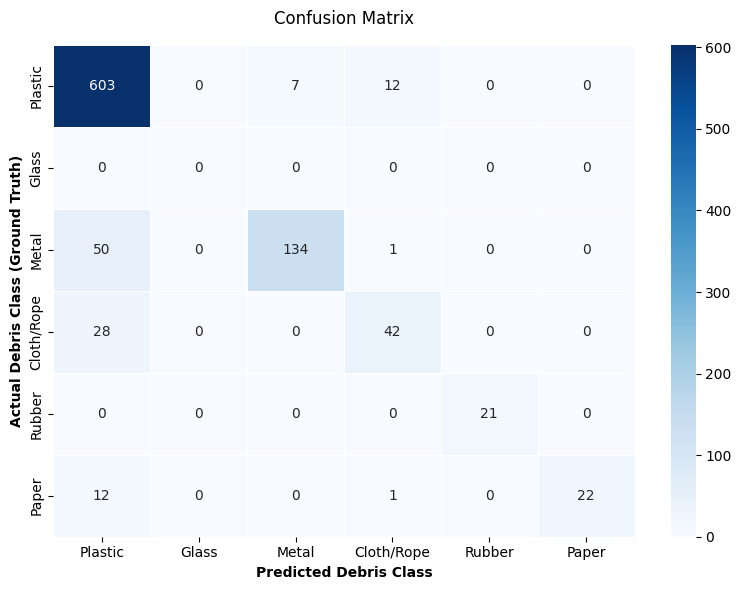

Evaluating Baseline A2 (SAM Images Only)...
Running inference on validation set...

--- Detailed Performance Metrics ---
              precision    recall  f1-score   support

     Plastic     0.7214    0.9325    0.8135       622
       Glass     0.0000    0.0000    0.0000         0
       Metal     0.5641    0.3568    0.4371       185
  Cloth/Rope     0.6667    0.0286    0.0548        70
      Rubber     0.8889    0.3810    0.5333        21
       Paper     0.0000    0.0000    0.0000        35

    accuracy                         0.7031       933
   macro avg     0.4735    0.2831    0.3064       933
weighted avg     0.6628    0.7031    0.6451       933



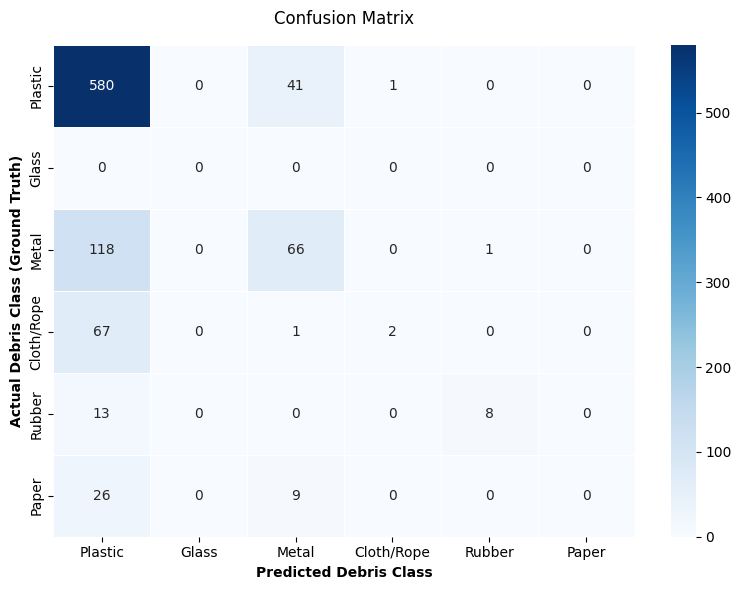

Evaluating Baseline A3 (Simple Concat Fusion)...
Running inference on validation set...

--- Detailed Performance Metrics ---
              precision    recall  f1-score   support

     Plastic     0.8714    0.9807    0.9228       622
       Glass     0.0000    0.0000    0.0000         0
       Metal     0.9527    0.7622    0.8468       185
  Cloth/Rope     0.9024    0.5286    0.6667        70
      Rubber     0.9545    1.0000    0.9767        21
       Paper     0.9545    0.6000    0.7368        35

    accuracy                         0.8896       933
   macro avg     0.7726    0.6452    0.6917       933
weighted avg     0.8949    0.8896    0.8828       933



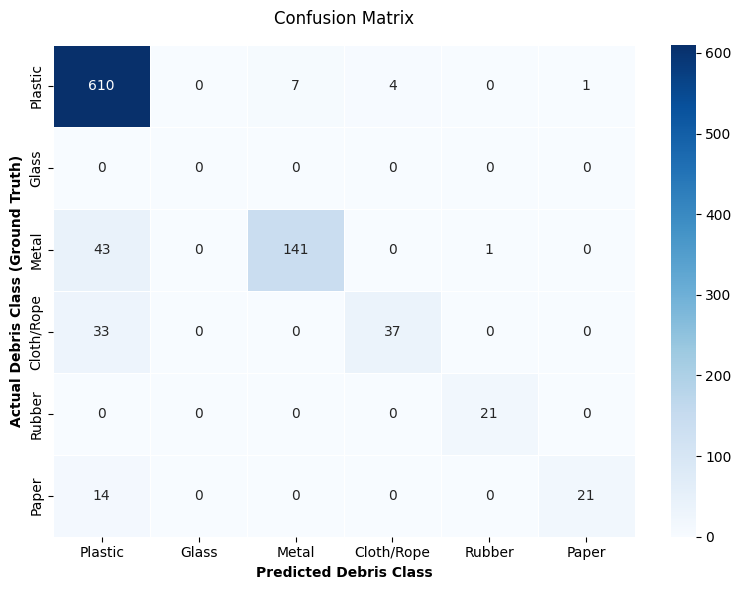

In [17]:
import torch
import torch.nn as nn
from torchvision import models

print("Loading saved checkpoints for evaluation...\n")

# --- Evaluate A1 (Original Only) ---
print("==================================================")
print("Evaluating Baseline A1 (Original Images Only)...")
model_a1_eval = models.mobilenet_v3_small(weights=None)
model_a1_eval.classifier[3] = nn.Linear(model_a1_eval.classifier[3].in_features, 6)
model_a1_eval.load_state_dict(torch.load('/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a1.pth'))
model_a1_eval = model_a1_eval.to(device)
evaluate_model(model_a1_eval, val_loader, 'single_orig', class_names)

# --- Evaluate A2 (SAM Segmented Only) ---
print("==================================================")
print("Evaluating Baseline A2 (SAM Images Only)...")
model_a2_eval = models.mobilenet_v3_small(weights=None)
model_a2_eval.classifier[3] = nn.Linear(model_a2_eval.classifier[3].in_features, 6)
model_a2_eval.load_state_dict(torch.load('/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a2.pth'))
model_a2_eval = model_a2_eval.to(device)
evaluate_model(model_a2_eval, val_loader, 'single_seg', class_names)

# --- Evaluate A3 (Simple Concat Fusion) ---
print("==================================================")
print("Evaluating Baseline A3 (Simple Concat Fusion)...")
model_a3_eval = SimpleConcatFusionNet(num_classes=6)
model_a3_eval.load_state_dict(torch.load('/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_a3.pth'))
model_a3_eval = model_a3_eval.to(device)
evaluate_model(model_a3_eval, val_loader, 'fusion', class_names)

Generating visual predictions for 4 random validation samples...



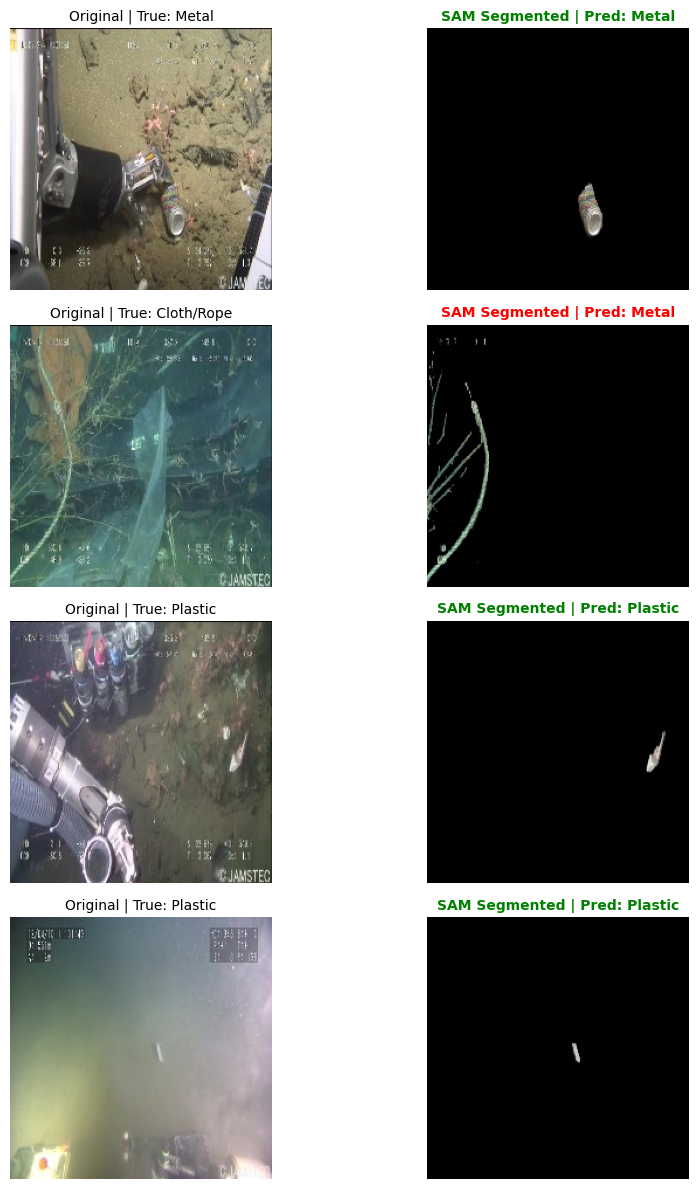

In [20]:
import torch
import matplotlib.pyplot as plt
import random

def safe_visualize_predictions(model, subset, class_names, num_samples=4):
    model.eval()

    try:
        indices = random.sample(range(len(subset)), num_samples)
    except Exception as e:
        print(f"🚨 Error selecting samples: {e}")
        return

    fig, axes = plt.subplots(num_samples, 2, figsize=(10, 3 * num_samples))
    if num_samples == 1:
        axes = axes.unsqueeze(0)

    print(f"Generating visual predictions for {num_samples} random validation samples...\n")

    try:
        with torch.no_grad():
            for i, idx in enumerate(indices):
                # Fetch data
                orig_tensor, seg_tensor, true_label_idx = subset[idx]

                # Add batch dim and move to GPU
                orig_batch = orig_tensor.unsqueeze(0).to(device)
                seg_batch = seg_tensor.unsqueeze(0).to(device)

                # Forward pass
                outputs = model(orig_batch, seg_batch)
                _, pred_label_idx = torch.max(outputs, 1)

                # Fix: pred_label_idx is a tensor, true_label_idx is already an int
                pred_idx = pred_label_idx.item()
                true_idx = true_label_idx if isinstance(true_label_idx, int) else true_label_idx.item()

                pred_name = class_names[pred_idx] if pred_idx < len(class_names) else str(pred_idx)
                true_name = class_names[true_idx] if true_idx < len(class_names) else str(true_idx)

                # Un-normalize images
                mean = torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
                std = torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

                orig_img_disp = (orig_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()
                seg_img_disp = (seg_tensor * std + mean).clamp(0, 1).permute(1, 2, 0).numpy()

                color = 'green' if pred_idx == true_idx else 'red'

                # Plot Original Image
                axes[i, 0].imshow(orig_img_disp)
                axes[i, 0].set_title(f"Original | True: {true_name}", fontsize=10)
                axes[i, 0].axis('off')

                # Plot SAM Segmented Image
                axes[i, 1].imshow(seg_img_disp)
                axes[i, 1].set_title(f"SAM Segmented | Pred: {pred_name}", fontsize=10, color=color, fontweight='bold')
                axes[i, 1].axis('off')

        plt.tight_layout()
        plt.show()
    except Exception as e:
        plt.close(fig)
        print(f"🚨 Runtime Error inside visualization loop: {e}")

# Run visualization on your proposed model (A5)
safe_visualize_predictions(model_proposed, val_subset, class_names, num_samples=4)

In [21]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim.lr_scheduler import CosineAnnealingLR
from torch.utils.data import DataLoader
from tqdm import tqdm
import copy
import numpy as np

# 1. Compute Class Weights from the training dataset to handle the Plastic bias
train_labels = [train_dataset[i][2] for i in train_subset.indices]
class_counts = np.bincount(train_labels, minlength=6)
# Inverse frequency weighting formula with safety for zero counts
total_samples = len(train_labels)
class_weights = total_samples / (len(class_counts) * class_counts.astype(float))
class_weights = torch.tensor(class_weights, dtype=torch.float).to(device)

print(f"📊 Computed Class Weights for Loss Function: {class_weights.cpu().numpy()}")

# 2. Re-initialize Proposed MDMAM Model
model_optimized = MDMAM_Net(num_classes=6).to(device)

# 3. Setup Weighted Loss, Optimizer, and Cosine Annealing Scheduler
criterion_weighted = nn.CrossEntropyLoss(weight=class_weights)
optimizer_opt = optim.AdamW(model_optimized.parameters(), lr=0.001, weight_decay=1e-4)

# Cosine annealing scales the learning rate down smoothly over 25 epochs
epochs = 25
scheduler = CosineAnnealingLR(optimizer_opt, T_max=epochs, eta_min=1e-6)

patience = 4 # Slightly increased patience for smooth annealing
best_val_loss_opt = float('inf')
epochs_no_improve_opt = 0
best_model_wts_opt = copy.deepcopy(model_optimized.state_dict())

print("🚀 Starting Optimized Training for Proposed MDMAM (With Class Weights & Cosine Annealing)...")

# 4. Optimized Training Loop
for epoch in range(epochs):
    model_optimized.train()
    running_loss = 0.0

    loop = tqdm(train_loader, desc=f"Epoch {epoch+1}/{epochs} [Train]", leave=False)
    for orig_img, seg_img, labels in loop:
        orig_img, seg_img, labels = orig_img.to(device), seg_img.to(device), labels.to(device)

        optimizer_opt.zero_grad()
        outputs = model_optimized(orig_img, seg_img)
        loss = criterion_weighted(outputs, labels)
        loss.backward()

        # Gradient clipping to stabilize attention layer updates
        torch.nn.utils.clip_grad_norm_(model_optimized.parameters(), max_norm=1.0)

        optimizer_opt.step()
        running_loss += loss.item()

    avg_train_loss = running_loss / len(train_loader)

    # Step the learning rate scheduler
    scheduler.step()

    # --- VALIDATION ---
    model_optimized.eval()
    val_loss = 0.0
    corrects = 0

    with torch.no_grad():
        for orig_img, seg_img, labels in val_loader:
            orig_img, seg_img, labels = orig_img.to(device), seg_img.to(device), labels.to(device)
            outputs = model_optimized(orig_img, seg_img)
            loss = criterion_weighted(outputs, labels)
            val_loss += loss.item()

            _, preds = torch.max(outputs, 1)
            corrects += torch.sum(preds == labels.data)

    avg_val_loss = val_loss / len(val_loader)
    val_acc = corrects.double() / val_size
    current_lr = scheduler.get_last_lr()[0]

    print(f"Epoch {epoch+1}/{epochs} | Train Loss: {avg_train_loss:.4f} | Val Loss: {avg_val_loss:.4f} | Val Acc: {val_acc:.4f} | LR: {current_lr:.6f}")

    # --- EARLY STOPPING ---
    if avg_val_loss < best_val_loss_opt:
        best_val_loss_opt = avg_val_loss
        best_model_wts_opt = copy.deepcopy(model_optimized.state_dict())
        epochs_no_improve_opt = 0
        torch.save(best_model_wts_opt, '/content/drive/MyDrive/MarineSAM_Project/models/checkpoints/best_model_optimized_a5.pth')
    else:
        epochs_no_improve_opt += 1
        if epochs_no_improve_opt >= patience:
            print("🛑 Early stopping triggered!")
            break

model_optimized.load_state_dict(best_model_wts_opt)
print("✅ Optimized Training Complete! Saved to Google Drive.")

/tmp/ipykernel_3327/1645036667.py:15: RuntimeWarning: divide by zero encountered in divide
  class_weights = total_samples / (len(class_counts) * class_counts.astype(float))


📊 Computed Class Weights for Loss Function: [0.24879904        inf 0.8680168  2.0444078  6.755435   5.222689  ]
🚀 Starting Optimized Training for Proposed MDMAM (With Class Weights & Cosine Annealing)...


Epoch 1/25 | Train Loss: 1.3537 | Val Loss: 2.3646 | Val Acc: 0.3837 | LR: 0.000996


Epoch 2/25 | Train Loss: 0.5569 | Val Loss: 4.5838 | Val Acc: 0.3773 | LR: 0.000984


Epoch 3/25 | Train Loss: 0.4065 | Val Loss: 0.7885 | Val Acc: 0.7642 | LR: 0.000965


Epoch 4/25 | Train Loss: 0.3347 | Val Loss: 0.5323 | Val Acc: 0.7921 | LR: 0.000938


... (2 outputs left out)

Epoch 7/25 | Train Loss: 0.1540 | Val Loss: 0.8350 | Val Acc: 0.7546 | LR: 0.000819


Epoch 8/25 | Train Loss: 0.1485 | Val Loss: 0.6746 | Val Acc: 0.8950 | LR: 0.000768


Epoch 9/25 | Train Loss: 0.1065 | Val Loss: 0.8135 | Val Acc: 0.6174 | LR: 0.000713


Epoch 10/25 | Train Loss: 0.1035 | Val Loss: 0.9711 | Val Acc: 0.8692 | LR: 0.000655
🛑 Early stopping triggered!
✅ Optimized Training Complete! Saved to Google Drive.


Evaluating Optimized Proposed MDMAM Model...
Running inference on validation set...

--- Detailed Performance Metrics ---
              precision    recall  f1-score   support

     Plastic     0.9305    0.8392    0.8825       622
       Glass     0.0000    0.0000    0.0000         0
       Metal     0.6364    0.9081    0.7483       185
  Cloth/Rope     0.9412    0.6857    0.7934        70
      Rubber     1.0000    0.9048    0.9500        21
       Paper     0.8947    0.9714    0.9315        35

    accuracy                         0.8478       933
   macro avg     0.7338    0.7182    0.7176       933
weighted avg     0.8732    0.8478    0.8526       933



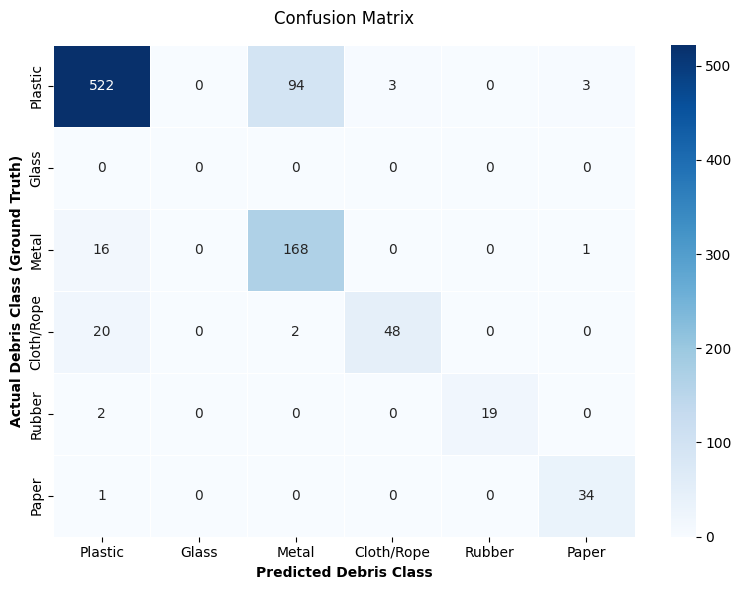

In [22]:
# Evaluate the newly optimized model (model_optimized)
print("Evaluating Optimized Proposed MDMAM Model...")
evaluate_model(model_optimized, val_loader, 'fusion', class_names)